In [ ]:
%pip install astroquery astropy pandas matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 36.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astroquery.vizier import Vizier
from astropy.cosmology import FlatLambdaCDM

# Retrieve all rows and the columns needed for our project
Vizier.ROW_LIMIT = -1

catalog = Vizier(
    columns=[
        "SLACS", "zl", "zs",
        "thetaE", "Mtotlen", "e_Mtotlen"
    ],
    catalog="J/A+A/501/461/lens"
).query_constraints()

# Inspect the returned tables
print(catalog)

TableList with 1 tables:
	'0:J/A+A/501/461/lens' with 6 column(s) and 50 row(s) 


In [ ]:
# Select the first returned table
df = catalog[0].to_pandas()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head())

# Remove rows missing any required measurement
df = df.dropna(
    subset=["zl", "zs", "thetaE", "Mtotlen"]
).copy()

# Keep physically valid lens-source configurations
df = df[
    (df["zl"] > 0) &
    (df["zs"] > df["zl"]) &
    (df["thetaE"] > 0) &
    (df["Mtotlen"] > 0)
].copy()

print("\nCleaned dataset shape:", df.shape)

Dataset shape: (50, 6)

Column names:
['SLACS', 'zl', 'zs', 'thetaE', 'Mtotlen', 'e_Mtotlen']

First five rows:
        SLACS     zl     zs  thetaE  Mtotlen  e_Mtotlen
0  J0008-0004  0.440  1.192    1.16       35          4
1  J0029-0055  0.227  0.931    0.96       12          1
2  J0037-0942  0.196  0.632    1.53       29          3
3  J0044+0113  0.120  0.197    0.79        9          1
4  J0109+1500  0.294  0.525    0.69       13          1

Cleaned dataset shape: (50, 6)


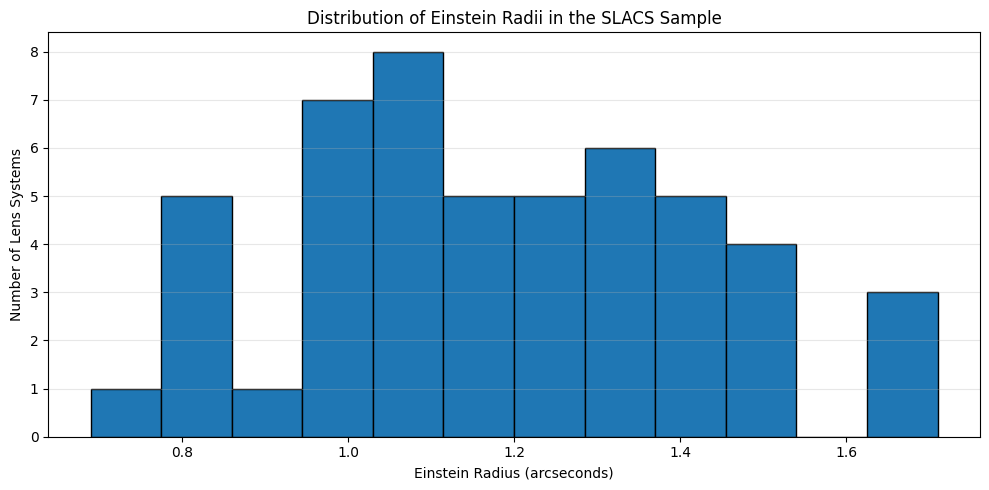

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df["thetaE"], bins=12, edgecolor="black")

plt.xlabel("Einstein Radius (arcseconds)")
plt.ylabel("Number of Lens Systems")
plt.title("Distribution of Einstein Radii in the SLACS Sample")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Calculation of Angular-Diameter Distances

The lens redshift $z_l$ and source redshift $z_s$ describe the cosmological positions of the foreground lens and the background source. To estimate the lens mass using gravitational lensing, we need the angular-diameter distances $D_L$, $D_S$, and $D_{LS}$. These distances are calculated using a flat cosmological model with specified values of the Hubble constant and matter density parameter.

In [ ]:
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

# Adopt a flat Lambda-CDM cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

# Calculate angular-diameter distances in Gpc
df["D_L_Gpc"] = cosmo.angular_diameter_distance(
    df["zl"].values
).to_value(u.Gpc)

df["D_S_Gpc"] = cosmo.angular_diameter_distance(
    df["zs"].values
).to_value(u.Gpc)

df["D_LS_Gpc"] = cosmo.angular_diameter_distance_z1z2(
    df["zl"].values,
    df["zs"].values
).to_value(u.Gpc)

df[["SLACS", "zl", "zs",
    "D_L_Gpc", "D_S_Gpc", "D_LS_Gpc"]].head()

,SLACS,zl,zs,D_L_Gpc,D_S_Gpc,D_LS_Gpc
0,J0008-0004,0.440,1.192,1.172744,1.708956,0.938540
1,J0029-0055,0.227,0.931,0.750391,1.622253,1.145438
2,J0037-0942,0.196,0.632,0.669889,1.411834,0.920910
3,J0044+0113,0.120,0.197,0.446200,0.672576,0.255079
4,J0109+1500,0.294,0.525,0.905964,1.291699,0.522966


### Estimation of Lens Mass

For an idealized, spherically symmetric lens, the Einstein radius relates the gravitational lens mass to the angular-diameter distances. By rearranging the Einstein-radius equation, the mass enclosed within the Einstein radius can be estimated from the observed angular radius and the calculated distances.

$$
M_E=\frac{c^2}{4G}\theta_E^2\frac{D_LD_S}{D_{LS}}
$$

The Einstein radius must be converted from arcseconds to radians before using the equation. The result is then converted from kilograms to solar masses.

In [ ]:
import numpy as np

G = 6.67430e-11
c = 299792458.0
M_sun = 1.98847e30
Gpc = 3.085677581e25

# Convert Einstein radius from arcseconds to radians
theta_rad = (
    df["thetaE"].to_numpy() * np.pi / (180 * 3600)
)

# Convert distances from Gpc to metres
D_L = df["D_L_Gpc"].to_numpy() * Gpc
D_S = df["D_S_Gpc"].to_numpy() * Gpc
D_LS = df["D_LS_Gpc"].to_numpy() * Gpc

# Calculate enclosed lensing mass
df["M_calculated"] = (
    (c**2 / (4 * G))
    * theta_rad**2
    * D_L * D_S / D_LS
    / M_sun
)

# Catalog mass is in units of 10^10 solar masses
df["M_published"] = df["Mtotlen"] * 1e10

df["Mass_ratio"] = df["M_calculated"] / df["M_published"]

df[["SLACS", "thetaE",
    "M_calculated", "M_published",
    "Mass_ratio"]].head()

,SLACS,thetaE,M_calculated,M_published,Mass_ratio
0,J0008-0004,1.16,3.528206e+11,3.500000e+11,1.008059
1,J0029-0055,0.96,1.202636e+11,1.200000e+11,1.002197
2,J0037-0942,1.53,2.951951e+11,2.900000e+11,1.017914
3,J0044+0113,0.79,9.015844e+10,9.000000e+10,1.001760
4,J0109+1500,0.69,1.308140e+11,1.300000e+11,1.006261


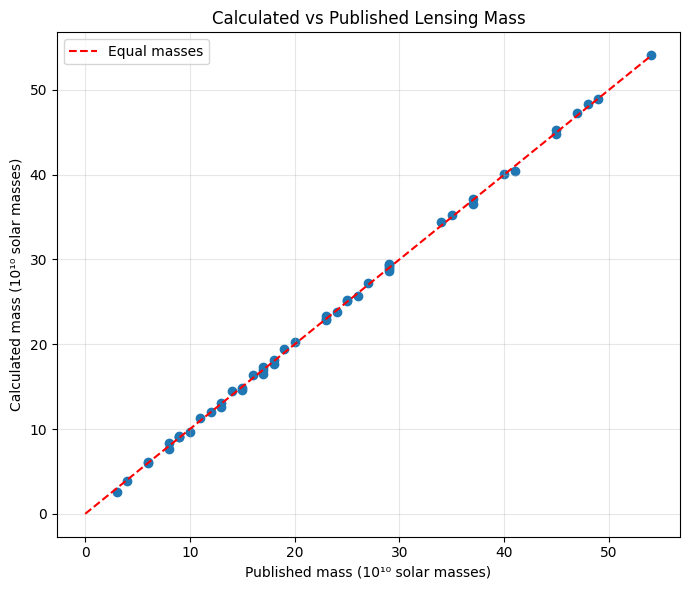

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    df["M_published"] / 1e10,
    df["M_calculated"] / 1e10
)

limit = max(
    df["M_published"].max(),
    df["M_calculated"].max()
) / 1e10

plt.plot([0, limit], [0, limit], "r--", label="Equal masses")

plt.xlabel("Published mass (10¹⁰ solar masses)")
plt.ylabel("Calculated mass (10¹⁰ solar masses)")
plt.title("Calculated vs Published Lensing Mass")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Comparison of Calculated and Published Lensing Masses

The calculated lensing masses are compared with the masses reported in the observational catalog. The relative percentage difference is used to quantify their agreement. This comparison checks the consistency of the implemented equation and units with the catalog values; it does not independently establish the accuracy of the adopted gravitational-lensing model.

In [ ]:
# Calculate relative percentage difference
df["Percentage_difference"] = (
    (df["M_calculated"] - df["M_published"])
    / df["M_published"]
) * 100

print("Mean absolute percentage difference:",
      df["Percentage_difference"].abs().mean(), "%")

print("Maximum absolute percentage difference:",
      df["Percentage_difference"].abs().max(), "%")

print("\nLargest differences:")
print(
    df[["SLACS", "M_calculated",
        "M_published", "Percentage_difference"]]
    .assign(Percentage_difference=lambda x:
            x["Percentage_difference"].round(3))
    .sort_values("Percentage_difference",
                 key=abs, ascending=False)
    .head(10)
)

Mean absolute percentage difference: 1.6028679067632785 %
Maximum absolute percentage difference: 13.353235877986972 %

Largest differences:
         SLACS  M_calculated   M_published  Percentage_difference
9   J0405-0455  2.599403e+10  3.000000e+10                -13.353
20  J0959+0410  7.585426e+10  8.000000e+10                 -5.182
44  J1451-0239  8.363833e+10  8.000000e+10                  4.548
40  J1420+6019  3.831558e+10  4.000000e+10                 -4.211
28  J1134+6027  1.254235e+11  1.300000e+11                 -3.520
38  J1403+0006  9.660480e+10  1.000000e+11                 -3.395
34  J1213+6708  1.446549e+11  1.400000e+11                  3.325
29  J1142+1001  1.654377e+11  1.700000e+11                 -2.684
21  J1016+3859  1.464660e+11  1.500000e+11                 -2.356
31  J1153+4612  1.125760e+11  1.100000e+11                  2.342


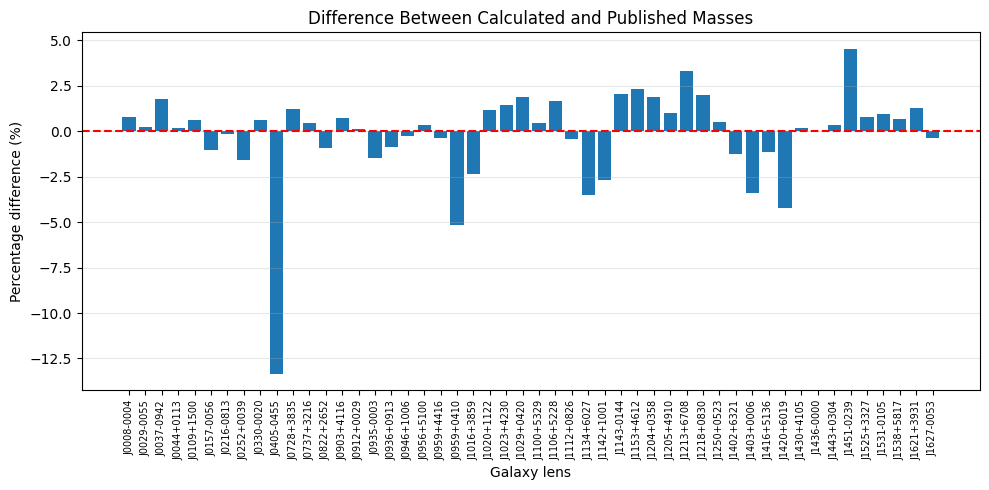

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(df["SLACS"], df["Percentage_difference"])
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Galaxy lens")
plt.ylabel("Percentage difference (%)")
plt.title("Difference Between Calculated and Published Masses")
plt.xticks(rotation=90, fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()